In [1]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("/content/Iris.csv")

In [4]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [5]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

In [6]:
le = {}
df_enc = df.copy()
for col in df_enc.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df_enc[col])
df_enc

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,8,14,4,1,0
1,1,6,9,4,1,0
2,2,4,11,3,1,0
3,3,3,10,5,1,0
4,4,7,15,4,1,0
...,...,...,...,...,...,...
145,145,24,9,28,19,2
146,146,20,4,26,15,2
147,147,22,9,28,16,2
148,148,19,13,30,19,2


In [8]:
x = df_enc[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
y = df_enc['Species']
x

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,8,14,4,1
1,6,9,4,1
2,4,11,3,1
3,3,10,5,1
4,7,15,4,1
...,...,...,...,...
145,24,9,28,19
146,20,4,26,15
147,22,9,28,16
148,19,13,30,19


In [9]:
model = CategoricalNB()
model.fit(x,y)

CategoricalNB()

In [11]:
test = [['1',	'5.1',	'3.5',	'1.4',	'0.2', 'Iris-setosa']]
test

[['1', '5.1', '3.5', '1.4', '0.2', 'Iris-setosa']]

In [16]:
print("\n---- Prediction ----------------------------------")
for t in test:
  # Convert the features to floats to match how they were fitted/encoded
  row = [[
      le['SepalLengthCm'].transform([float(t[1])])[0],
      le['SepalWidthCm'].transform([float(t[2])])[0],
      le['PetalLengthCm'].transform([float(t[3])])[0],
      le['PetalWidthCm'].transform([float(t[4])])[0]
  ]]

  pred = le['Species'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]

  print(f"Input : SepalLengthCm =({t[1]}) SepalWidthCm =({t[2]}) PetalLengthCm =({t[3]}) PetalWidthCm =({t[4]})")
  print(f"Output: Species =({pred})")
  print(f"Result : Species -> {pred}")
  print(f"Probabilities: ")
  for class_idx, class_label in enumerate(le['Species'].classes_):
      print(f"  P({class_label}) = {prob[class_idx]:.4f}")
  print("--------------------------------------------------")


---- Prediction ----------------------------------
Input : SepalLengthCm =(5.1) SepalWidthCm =(3.5) PetalLengthCm =(1.4) PetalWidthCm =(0.2)
Output: Species =(Iris-setosa)
Result : Species -> Iris-setosa
Probabilities: 
  P(Iris-setosa) = 0.9999
  P(Iris-versicolor) = 0.0001
  P(Iris-virginica) = 0.0000
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [14]:
from sklearn.metrics import accuracy_score

# Re-fit the model using the correct features (x, y)
model.fit(x, y)

y_pred = model.predict(x)
print(f"\n Training Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


 Training Accuracy: 96.67%


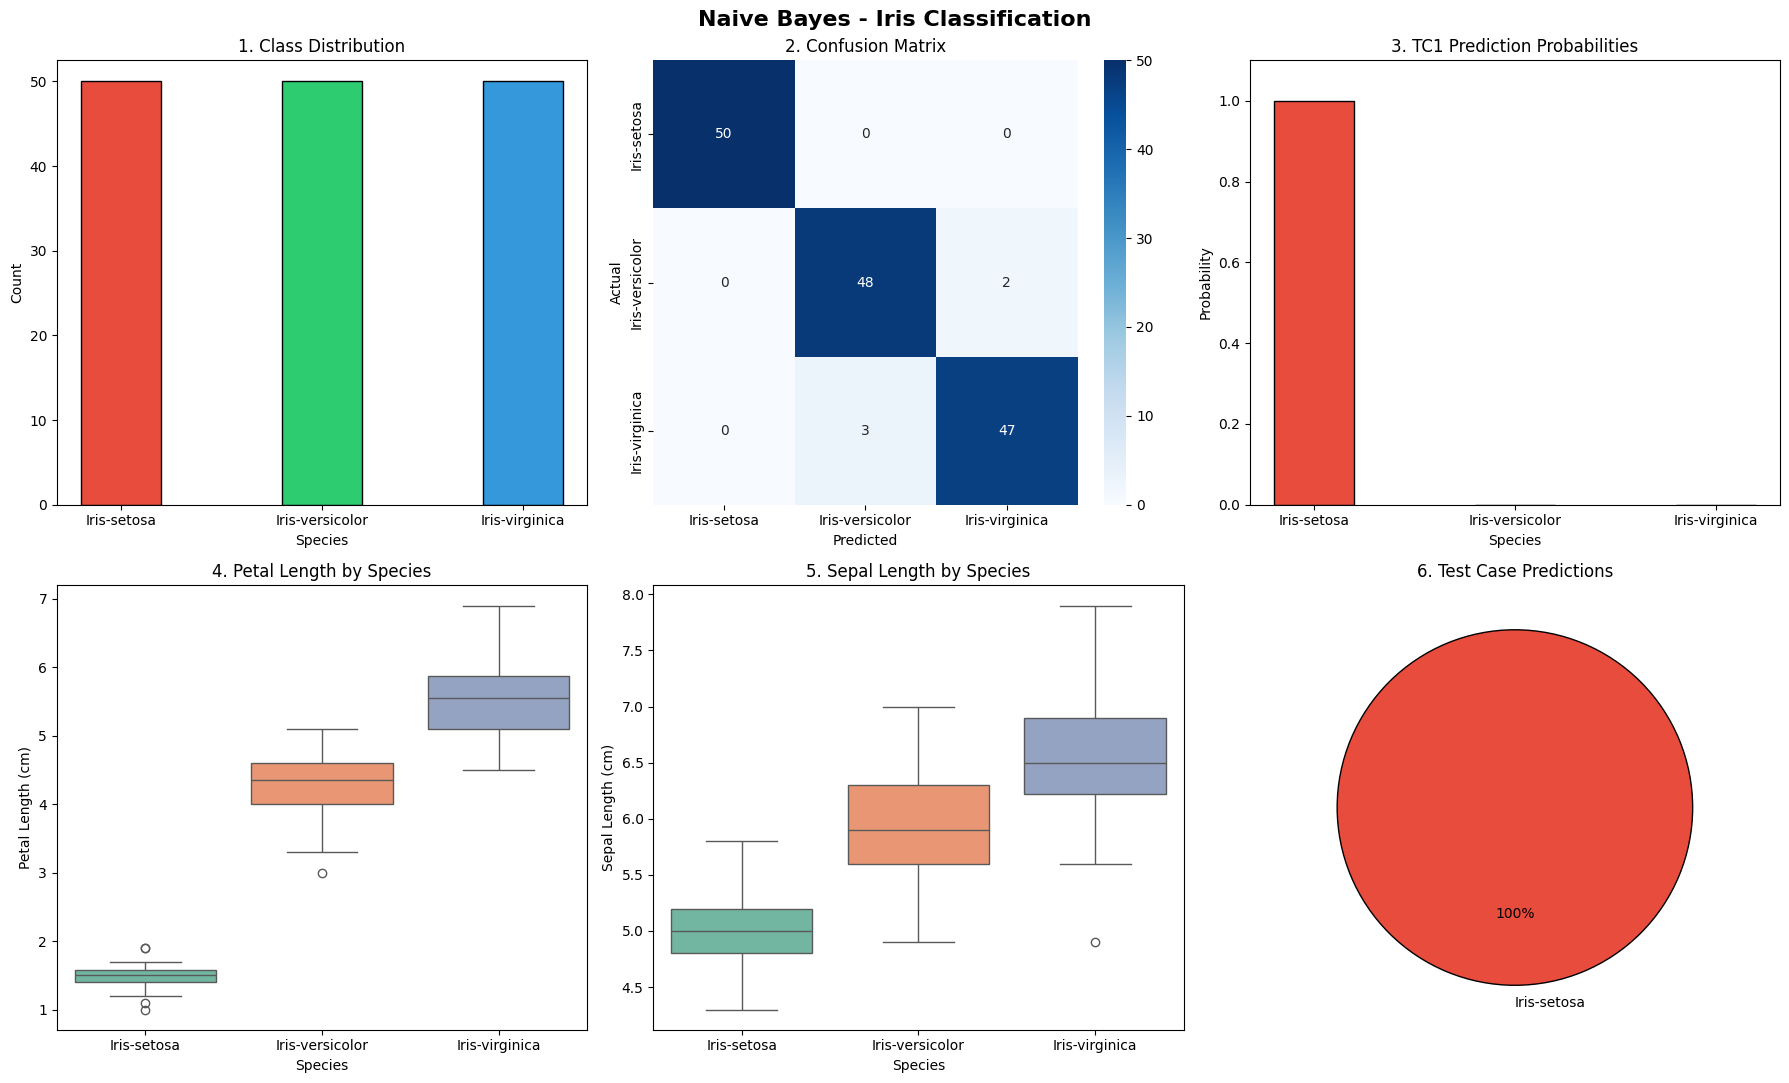

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Configure subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Iris Classification", fontsize=16, fontweight='bold')

# 1. Class Distribution
counts = df['Species'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71', '#3498db'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Species")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
class_labels = le['Species'].classes_
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, ax=axes[0, 1], fmt='d')
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities for TC1
class_names = le['Species'].classes_
axes[0, 2].bar(class_names, prob, color=['#e74c3c', '#2ecc71', '#3498db'], edgecolor='black', width=0.4)
axes[0, 2].set_title("3. TC1 Prediction Probabilities")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].set_xlabel("Species")
axes[0, 2].set_ylabel("Probability")

# 4. Feature Distribution: PetalLengthCm vs Species (Fixed FutureWarning)
sns.boxplot(data=df, x='Species', y='PetalLengthCm', hue='Species', ax=axes[1, 0], palette='Set2', legend=False)
axes[1, 0].set_title("4. Petal Length by Species")
axes[1, 0].set_xlabel("Species")
axes[1, 0].set_ylabel("Petal Length (cm)")

# 5. Feature Distribution: SepalLengthCm vs Species
sns.boxplot(data=df, x='Species', y='SepalLengthCm', hue='Species', ax=axes[1, 1], palette='Set2', legend=False)
axes[1, 1].set_title("5. Sepal Length by Species")
axes[1, 1].set_xlabel("Species")
axes[1, 1].set_ylabel("Sepal Length (cm)")

# Hide unused subplots
axes[1, 2].axis('off')

# 6. Test Case Predictions
predictions = [pred]
pred_series = pd.Series(predictions)
pred_counts = pred_series.value_counts()
colors_pie = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.0f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()